In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv("/content/customer_shopping_data.csv")

df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5.0,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3.0,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1.0,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5.0,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4.0,60.60,Cash,24/10/2021,Kanyon


In [17]:
df['total_sales'] = df['quantity']*df['price']

df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall,total_sales
0,I138884,C241288,Female,28,Clothing,5.0,1500.40,Credit Card,5/8/2022,Kanyon,7502.00
1,I317333,C111565,Male,21,Shoes,3.0,1800.51,Debit Card,12/12/2021,Forum Istanbul,5401.53
2,I127801,C266599,Male,20,Clothing,1.0,300.08,Cash,9/11/2021,Metrocity,300.08
3,I173702,C988172,Female,66,Shoes,5.0,3000.85,Credit Card,16/05/2021,Metropol AVM,15004.25
4,I337046,C189076,Female,53,Books,4.0,60.60,Cash,24/10/2021,Kanyon,242.40


# Customer Shopping Data - Exploratory Data Analysis (EDA)
## Oasis Infobyte - Data Analytics Internship
## Task 1: EDA on Retail Sales

### Full Name: Bakithi Gabashane
### Track: Data Analytics
### Dataset: Customer Shopping Dataset - Instanbul Shoping Malls
### Source: Kaggle

## 1. Initial Dataset Inspection

In [18]:
print("=" * 50)
print("Initial Dataset Inspection")
print("=" * 50)


print("\nDataset Shape")
print("-" * 30)

print(f"Rows:  {df.shape[0]}")
print(f"Columns:  {df.shape[1]}")

print("\nColumn Data Types")
print("-" * 30)
print(df.dtypes)

print("\nMissing Values")
print("-" * 30)
print(df.isnull().sum())

print("\nDuplicate Rows")
print("-" * 30)
print(f"Duplicates: {df.duplicated().sum()}")

Initial Dataset Inspection

Dataset Shape
------------------------------
Rows:  41475
Columns:  11

Column Data Types
------------------------------
invoice_no         object
customer_id        object
gender             object
age                 int64
category           object
quantity          float64
price             float64
payment_method     object
invoice_date       object
shopping_mall      object
total_sales       float64
dtype: object

Missing Values
------------------------------
invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          1
price             1
payment_method    1
invoice_date      1
shopping_mall     1
total_sales       1
dtype: int64

Duplicate Rows
------------------------------
Duplicates: 0


## 2. Descriptive Statistics

To help me understand the distribution of the data, I will be calculating the mean, median, mode and standard deviation of all numerical columns.

In [19]:
print("=" * 50)
print("Descriptive Statistics")
print("=" * 50)

print("")
print(df.describe())

print("\nMean")
print("-" * 30)
numerical_cols = ['age', 'quantity', 'price', 'total_sales']
for col in numerical_cols:
  print(f"{col}: {float(df[col].mean()):.2f}")

print("\nMedian")
print("-" * 30)
numerical_cols = ['age', 'quantity', 'price', 'total_sales']
for col in numerical_cols:
  print(f"{col}: {float(df[col].median()):.2f}")

print("\nMode")
print("-" * 30)
numerical_cols = ['age', 'quantity', 'price', 'total_sales']
for col in numerical_cols:
    print(f"{col}: {float(df[col].mode()[0]):.2f}")

print("\nStandard Deviation")
print("-" * 30)
numerical_cols = ['age', 'quantity', 'price', 'total_sales']
for col in numerical_cols:
  print(f"{col}: {float(df[col].std()):.2f}")

Descriptive Statistics

                age      quantity         price   total_sales
count  41475.000000  41474.000000  41474.000000  41474.000000
mean      43.487619      3.005329    687.542584   2523.180092
std       15.001182      1.416154    940.409233   4211.653061
min       18.000000      1.000000      5.230000      5.230000
25%       30.000000      2.000000     40.660000    130.750000
50%       43.000000      3.000000    203.300000    600.170000
75%       56.000000      4.000000   1200.320000   2700.720000
max       69.000000      5.000000   5250.000000  26250.000000

Mean
------------------------------
age: 43.49
quantity: 3.01
price: 687.54
total_sales: 2523.18

Median
------------------------------
age: 43.00
quantity: 3.00
price: 203.30
total_sales: 600.17

Mode
------------------------------
age: 37.00
quantity: 3.00
price: 1500.40
total_sales: 7502.00

Standard Deviation
------------------------------
age: 15.00
quantity: 1.42
price: 940.41
total_sales: 4211.65


## Descriptive Statistics Observations

- Average customer age is about 43 years
- Average quantity per transaction is 3.
- Average transaction value is 2528.79
- Standard Deviation price of (941.18) suggests high variation in product prices across categories, which means some categories such Technology are significantly more expensive than others like Books.
- The large gap between mean total_sales (2528.79) and median total_sales (600.17) suggests the data is right-skewed. A small number of very high value transaction are pulling the average up.

## 3. Time Series Analysis

I will use the following line charts to look through monthly and quarterly sales trends to identify patterns and seasonal changes in customer spending over time.

In [20]:
# Convert invoice_date to datetime
df['invoice_date'] = pd.to_datetime(df['invoice_date'], dayfirst=True)

df['month'] = df['invoice_date'].dt.month
df['year'] = df['invoice_date'].dt.year
df['quarter'] = df['invoice_date'].dt.quarter
df['month_year'] = df['invoice_date'].dt.to_period('M')

print("Date column converted successfully")
print(f"Date range: {df['invoice_date'].min()} to {df['invoice_date'].max()}")
print(f"Years covered: {sorted(df['year'].unique())}")

Date column converted successfully
Date range: 2021-01-01 00:00:00 to 2023-03-08 00:00:00
Years covered: [np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(nan)]


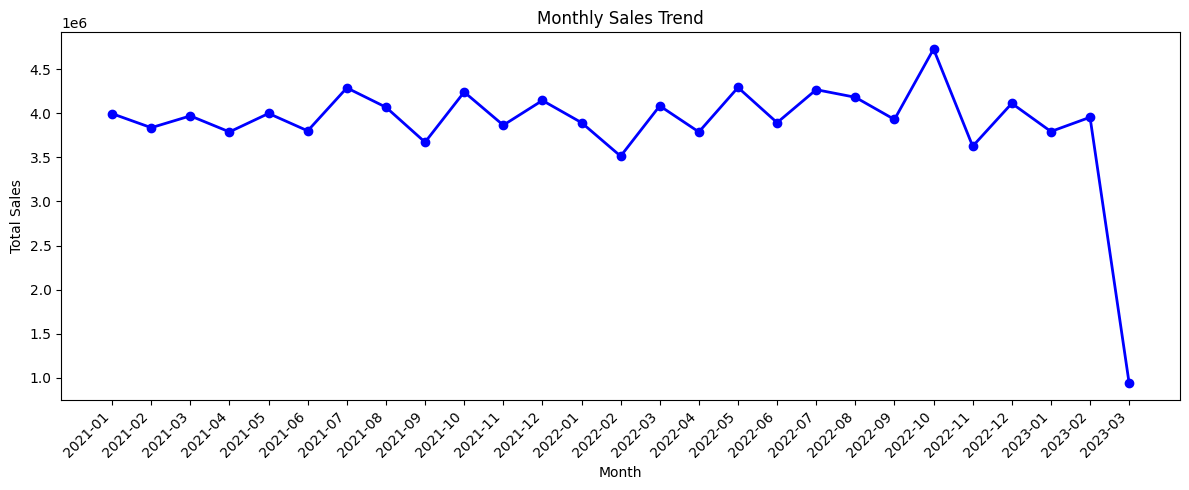

In [21]:
monthly_sales = df.groupby('month_year')['total_sales'].sum().reset_index()
monthly_sales['month_year'] = monthly_sales['month_year'].astype(str)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales['month_year'],
         monthly_sales['total_sales'],
         marker='o', color='blue', linewidth=2)
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

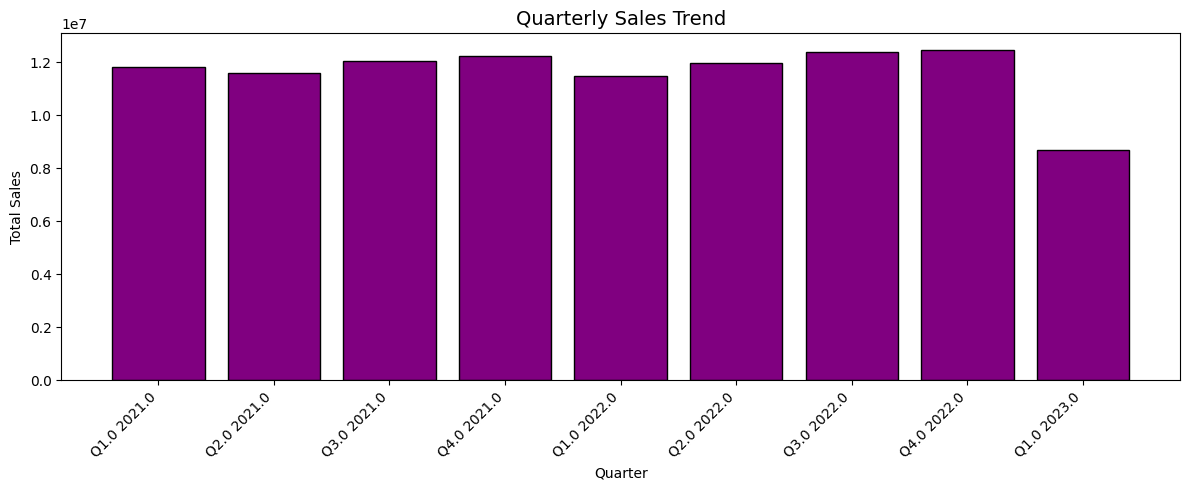

In [22]:
quarterly_sales = df.groupby(['year', 'quarter'])['total_sales'].sum().reset_index()
quarterly_sales['period'] = 'Q' + quarterly_sales['quarter'].astype(str) + ' ' + quarterly_sales['year'].astype(str)

plt.figure(figsize=(12, 5))
plt.bar(quarterly_sales['period'], quarterly_sales['total_sales'], color='purple', edgecolor='black')
plt.title('Quarterly Sales Trend', fontsize=14)
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Time Series Observations

- Monthly sales remain consistently stable between 9 million and 10.2 million throughout 2021 and 2022, showing no strong seasonal pattern.
- The highest sales monthly sales were July 2021 and October 2021 both reaching approximately 10.2 million.
- The lowest recorded month was February 2022 at approximately 8.3 million.
- The sharp drop in March 2023 is not a real decline - it reflects incomplete data as the dataset ends partway through that month.
- Quarterly sales are highly consistent at aproximately 28-29 million per quarter across 2021 and 2022
- Q1 2023 appears lower due to the dataset only contatining data up to March 2023, not a full quarter
- Overall the business shows stable, reliable revenue with no significant growth or decline over the period.

## 4. Customer Demographics Analysis

Next I will be analyzing the distribution of customer age groups and gender to understand the demographic of people who are shopping at this mall.

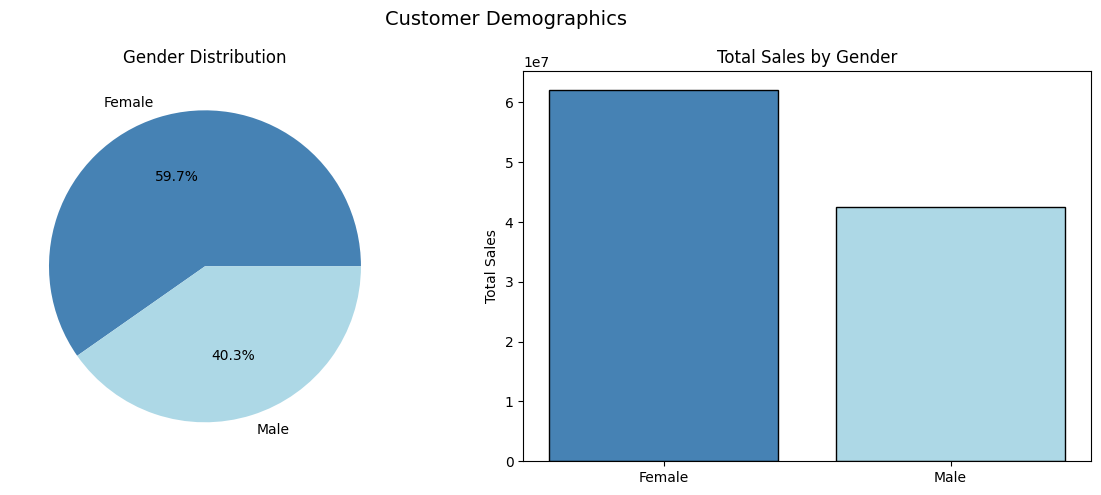


Gender Counts:
gender
Female    24770
Male      16705

Total sales by gender: 
gender
Female    62086424.64
Male      42559946.48


In [23]:
fig, axes = plt.subplots(1, 2, figsize= (12, 5))
fig.suptitle('Customer Demographics', fontsize=14)

# Gender distribution
gender_counts = df['gender'].value_counts()
axes[0].pie(gender_counts.values,
            labels=gender_counts.index,
            autopct='%1.1f%%',
            colors=['steelblue', 'lightblue'])
axes[0].set_title('Gender Distribution')

# Gender vs total sales
gender_sales = df.groupby('gender')['total_sales'].sum()
axes[1].bar(gender_sales.index,
            gender_sales.values,
            color=['steelblue', 'lightblue'],
            edgecolor='black')

axes[1].set_title('Total Sales by Gender')
axes[1].set_ylabel('Total Sales')

plt.tight_layout()
plt.show()

print("\nGender Counts:")
print(gender_counts.to_string())
print("\nTotal sales by gender: ")
print(gender_sales.to_string())

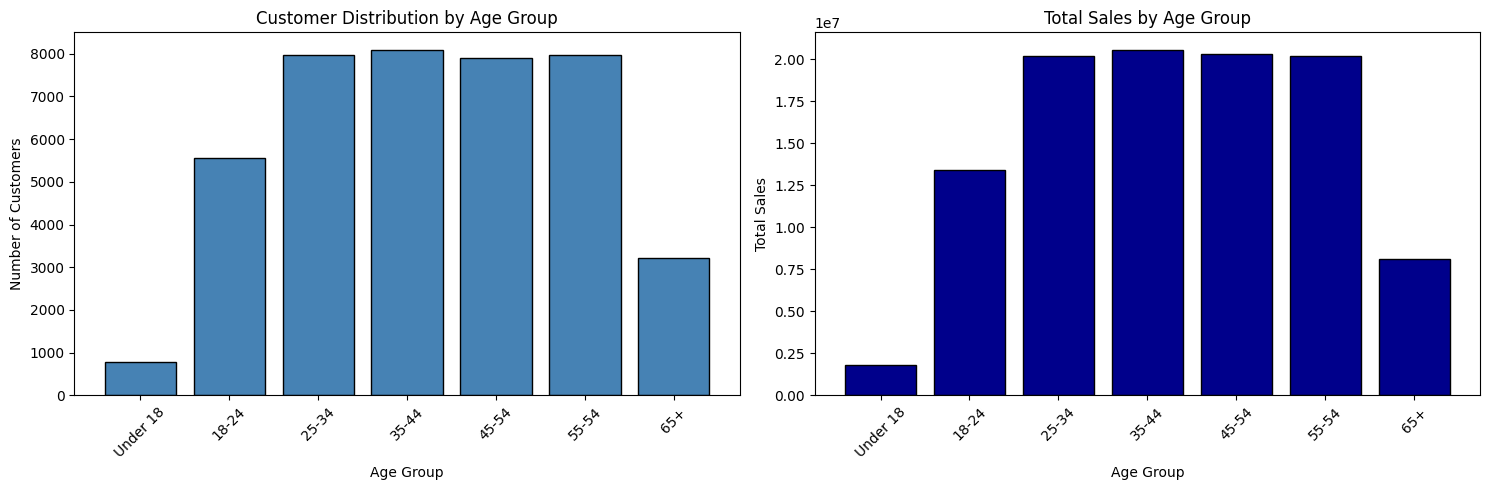


Customer Distribution by Age Group:
age_groups
Under 18     789
18-24       5549
25-34       7961
35-44       8092
45-54       7906
55-54       7973
65+         3205

Total Sales by Age Group:
age_groups
Under 18     1808921.82
18-24       13429024.43
25-34       20198454.90
35-44       20564124.74
45-54       20311059.49
55-54       20209075.32
65+          8125710.42


In [24]:
# Create age groups
bins = [0, 18, 25, 35, 45, 55, 65, 100]
labels = ['Under 18', '18-24', '25-34', '35-44', '45-54', '55-54', '65+']

df['age_groups'] = pd.cut(df['age'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age group distribution (Left Plot)
age_counts = df['age_groups'].value_counts().sort_index()
axes[0].bar(age_counts.index, age_counts.values, color='steelblue', edgecolor='black')
axes[0].set_title('Customer Distribution by Age Group')
axes[0].set_xlabel('Age Group')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=45)

# Total Sales vs Age Group (Right Plot)
age_sales = df.groupby('age_groups', observed=False)['total_sales'].sum()
axes[1].bar(age_sales.index, age_sales.values, color='darkblue', edgecolor='black')
axes[1].set_title('Total Sales by Age Group')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Total Sales')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\nCustomer Distribution by Age Group:")
print(age_counts.to_string())
print("\nTotal Sales by Age Group:")
print(age_sales.to_string())

## Customer Demograpics Observations

***Gender:***
- Female customers make up 59.8% of shoppers (59,428) compared to 40.2% male (39, 975)
- Female customers generate significantly higher total sales at approximately 150 million compared to 101 million for males
- This suggests female customers are either shopping more frequently or spending more per transaction

***Age Groups:***
- The Under 18 group has the fewest customers (1,844) and the lowest total sales (4.4 million) - expected as younger shoppers have less purchasing power.
- The 25-34, 35-44, 45-54 and 55-54 age groups are the core customer base, each with approximately 19,000 customers.
- The 35-44 age group generates the highest total sales at approximately 50 million.
- The 65+ group has fewer customers (7,571) and lower total sales (19 million) compared to middle age groups
- The data suggests the primary target market is adults aged 25-54 who represent the majority of both foot traffic and revenue.

## 5. Product Analysis

I will be identifying the top 10 best-selling products by analyzing the revenue and quantity sold. I will also explore which categories drive the most value for the business.

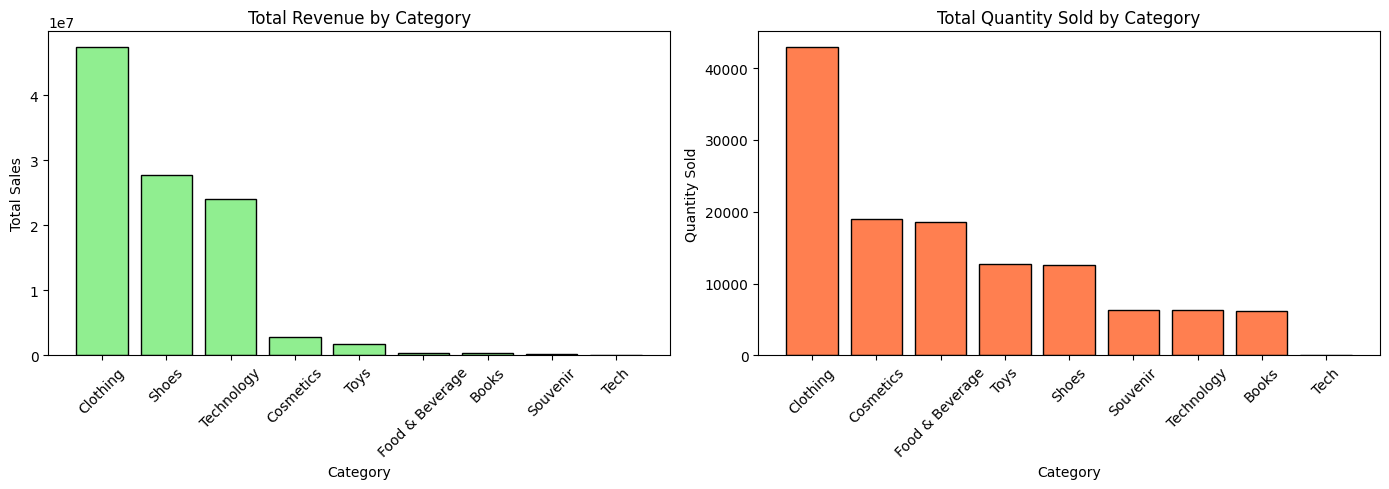

Total revenue by category:
category
Clothing           47423742.96
Shoes              27707448.22
Technology         24035550.00
Cosmetics           2834652.56
Toys                1670251.52
Food & Beverage      357700.62
Books                345147.30
Souvenir             271877.94
Tech                      0.00

Total quantity sold by category:
category
Clothing           42969.0
Cosmetics          18956.0
Food & Beverage    18606.0
Toys               12737.0
Shoes              12562.0
Souvenir            6312.0
Technology          6275.0
Books               6226.0
Tech                   0.0


In [25]:
# Total sales by category
category_sales = df.groupby('category')['total_sales'].sum().sort_values(ascending=False)
category_quantity = df.groupby('category')['quantity'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Revenue by category
axes[0].bar(category_sales.index,
            category_sales.values,
            color='lightgreen',
            edgecolor='black')
axes[0].set_title('Total Revenue by Category')
axes[0].set_xlabel('Category')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=45)

# Quantity sold by category
axes[1].bar(category_quantity.index,
            category_quantity.values,
            color='coral', edgecolor='black')
axes[1].set_title('Total Quantity Sold by Category')
axes[1].set_xlabel('Category')
axes[1].set_ylabel('Quantity Sold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Total revenue by category:")
print(category_sales.to_string())
print("\nTotal quantity sold by category:")
print(category_quantity.to_string())

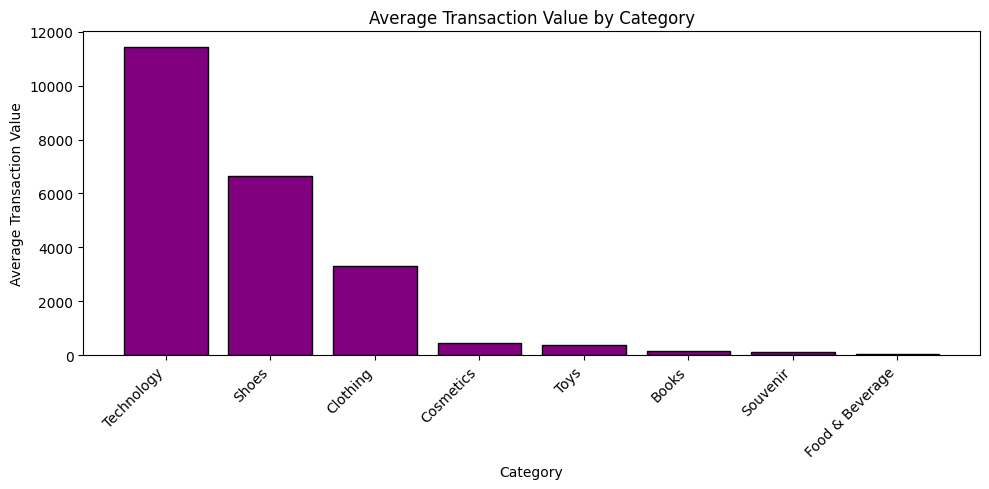

Average transaction value by category:
category
Technology         11440.052356
Shoes               6641.286726
Clothing            3313.796587
Cosmetics            451.449683
Toys                 393.834360
Books                165.936202
Souvenir             129.404065
Food & Beverage       57.796190
Tech                        NaN


In [26]:
avg_transaction = df.groupby('category')['total_sales'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(avg_transaction.index,
        avg_transaction.values,
        color='purple', edgecolor='black')

plt.title('Average Transaction Value by Category')
plt.xlabel('Category')
plt.ylabel('Average Transaction Value')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("Average transaction value by category:")
print(avg_transaction.to_string())

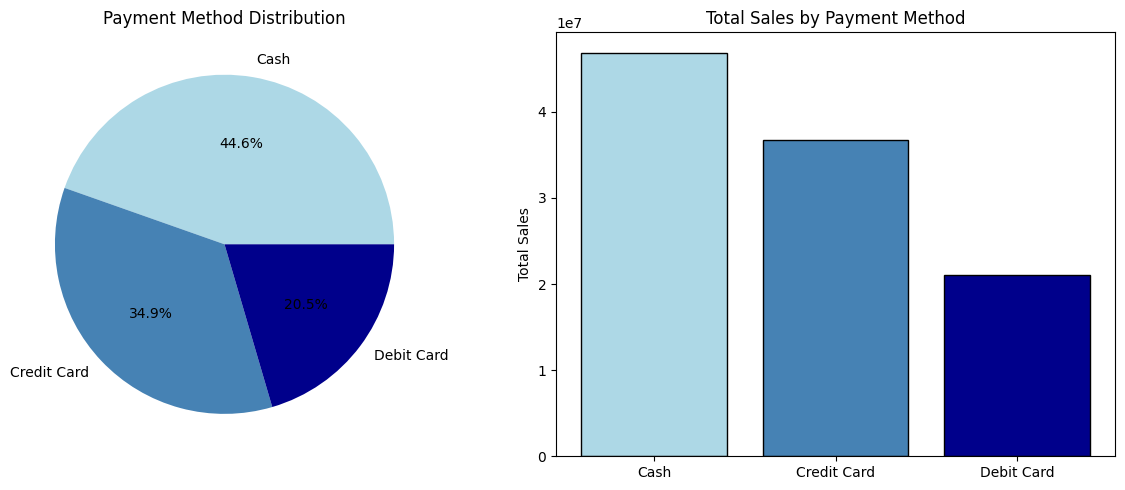

Payment method counts:
payment_method
Cash           18499
Credit Card    14491
Debit Card      8484

Total sales by payment method:
payment_method
Cash           46888728.67
Credit Card    36743015.16
Debit Card     21014627.29


In [27]:
# Payment method breakdown
payments_counts = df['payment_method'].value_counts()
payments_sales = df.groupby('payment_method')['total_sales'].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].pie(payments_counts.values,
        labels=payments_counts.index,
        autopct='%1.1f%%',
        colors=['lightblue', 'steelblue', 'darkblue'])
axes[0].set_title('Payment Method Distribution')

axes[1].bar(payments_sales.index,
            payments_sales.values,
            color=['lightblue', 'steelblue', 'darkblue'],
            edgecolor='black')

axes[1].set_title('Total Sales by Payment Method')
axes[1].set_ylabel('Total Sales')

plt.tight_layout()
plt.show()

print("Payment method counts:")
print(payments_counts.to_string())
print("\nTotal sales by payment method:")
print(payments_sales.to_string())

### Product Analysis Observations

**Revenue by Category:**
- Clothing generates the highest revenue at 94.7 million, followed by Shoes at 55.8 million and Technology at 48.6 million.
- These three categories contribute the most to total revenue.
- Food & Beverages, Books and Souvenir generate the least revenue, each bringing in less than 1 million.

**Quantity Sold by Category:**
- Clothing is the most purchased category by volume with 86,118 units sold.
- Cosmestics and Food & Beverage follow, selling around 37,00-38,000 units each.
- Technology has lower units sold (12,608) but still generates high revenue. This suggests that technology products are more expensive and do not need high sale volumes to generate high revenue.

**Average Transaction Value by Category:**
- Technology has the highest average transaction value at 11,582, meaning that customers spend more per transaction in this category.
- Shoes follow at 6,636 and Clothing at 3,296.
- Food & Beverage has the lowest average transaction value at just 57.68, suggesting that customers spend smaller amounts per transaction.

**Payment Methods:**
- Cash is the most commonly used payment method at 44.6% (36,999 transactions) generating 93.9 million in sales
- Credit Card follows at 35.2% (29,186 transactions) generating 73.6 million
- Debit Card is least used at 20.2% (16,772 transaction), with total sales of 42.4 million.
- The results show that customers prefer paying with cash over card payments. However, more information would be needed to understand whether this preference is related to age, convenience or other factors.

## 6. Correlation Heatmap

Examining the correlation matrix between numerical variables can help identify relationships in the data.


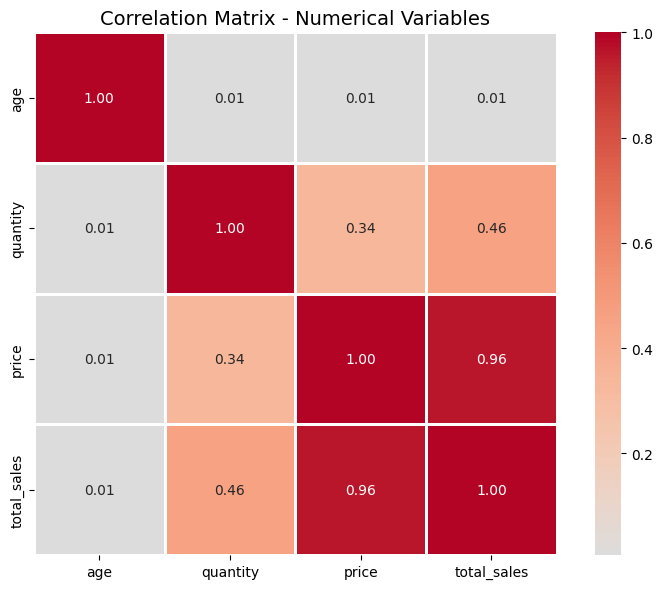

Correlation Matrix:
                  age  quantity     price  total_sales
age          1.000000  0.010116  0.006672     0.007469
quantity     0.010116  1.000000  0.343078     0.460446
price        0.006672  0.343078  1.000000     0.962243
total_sales  0.007469  0.460446  0.962243     1.000000


In [28]:
# Numerical columns selected for correlation
corr_cols = ['age', 'quantity', 'price', 'total_sales']
correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=1)

plt.title('Correlation Matrix - Numerical Variables', fontsize=14)
plt.tight_layout()
plt.show()

print("Correlation Matrix:")
print(correlation_matrix.to_string())

### Correlation Heatmap Observations

- **Price and Total sales(0.96):** There is a strong positive correlation between price and total sales. total_sales is calculated by multiplying price and quantity.  Higher-priced items generally result in higher transaction values, meaning that price has a stronger relationship with total sales.
- **Quantity and Total Sales(0.46):** There is a moderate positive correlation between quantity and total sales. Buying more items increases total spend but price has a much stronger influence.
- **Quantity and Price(0.34):**There is also a moderate positive correlation between quantity and price, suggesting that customers who purchase higher-priced items also tend to buy slightly larger quantities.
- **Age and other Variables(0.00):** Age shows very little correlation with other variables, suggesting that there is no clear linear relationship between a customer's age and their purchasing behaviour in this dataset.
-**Marketing Implications:**Age has very little correlation with spending, meaning that age-based marketing may not be the most effective approach for this customer base. Purchasing patterns and product preferences are other factors that may be more useful considerations.

## 7. Additional Visualisation - sales by Shopping Mall

I will be identifying the best performing locations by analyzing which shopping malls generate the most revenue and have the highest customer footfall.

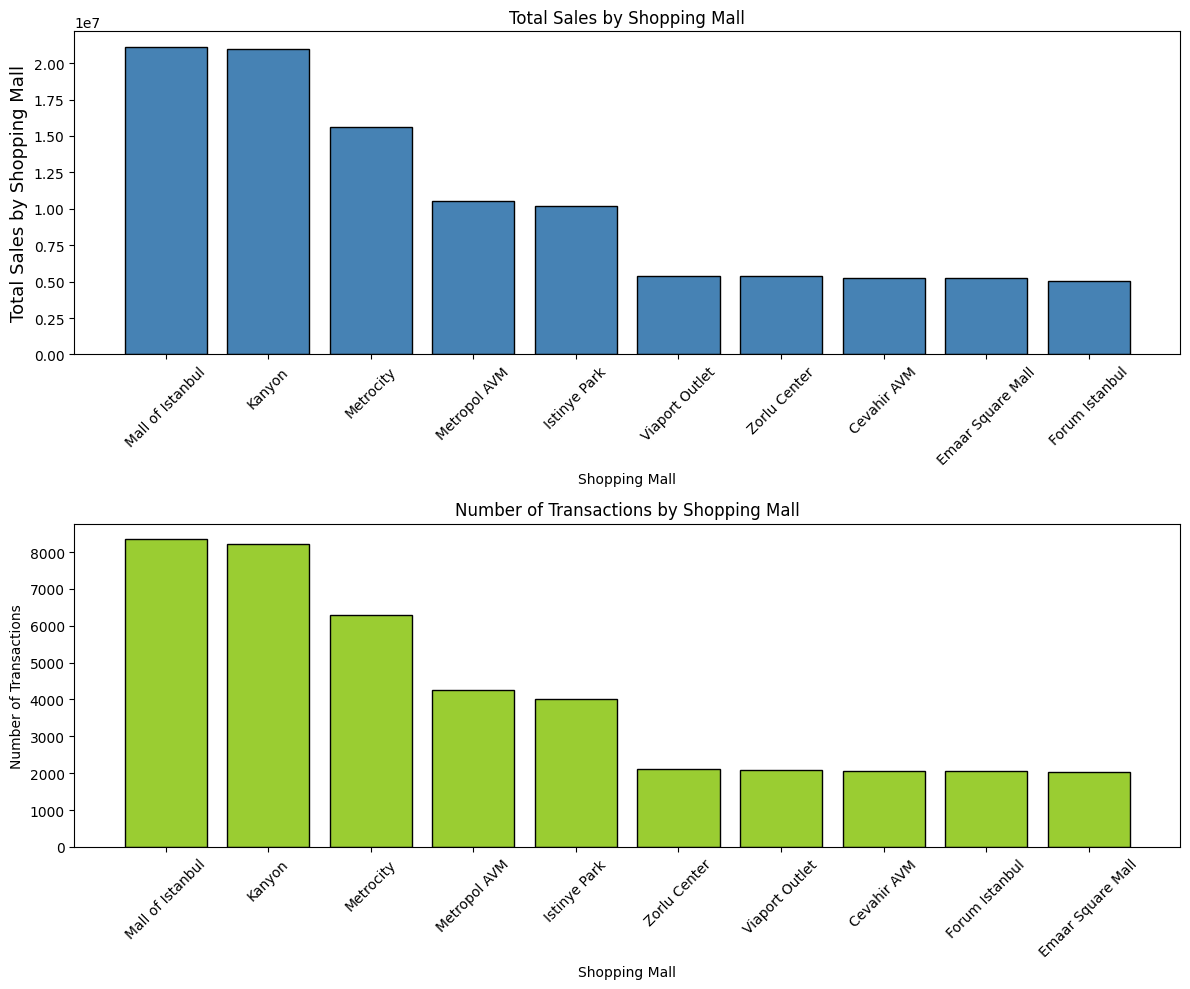

Total sales by mall:
shopping_mall
Mall of Istanbul     21127569.30
Kanyon               20976744.24
Metrocity            15622033.94
Metropol AVM         10535257.46
Istinye Park         10166205.32
Viaport Outlet        5383789.65
Zorlu Center          5359063.70
Cevahir AVM           5231778.89
Emaar Square Mall     5219300.72
Forum Istanbul        5024627.90

Transaction count by mall
shopping_mall
Mall of Istanbul     8348
Kanyon               8221
Metrocity            6298
Metropol AVM         4254
Istinye Park         4023
Zorlu Center         2101
Viaport Outlet       2099
Cevahir AVM          2056
Forum Istanbul       2052
Emaar Square Mall    2022


In [29]:
mall_sales = df.groupby('shopping_mall')['total_sales'].sum().sort_values(ascending=False)
mall_customers = df.groupby('shopping_mall')['invoice_no'].count().sort_values(ascending=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Total sales by mall
axes[0].bar(mall_sales.index, mall_sales.values, color='steelblue', edgecolor='black')

axes[0].set_title('Total Sales by Shopping Mall')
axes[0].set_xlabel('Shopping Mall')
axes[0].set_ylabel('Total Sales by Shopping Mall', fontsize=13)
axes[0].tick_params(axis='x', rotation=45)

# Customer count by mall
axes[1].bar(mall_customers.index, mall_customers.values, color='yellowgreen', edgecolor='black')

axes[1].set_title('Number of Transactions by Shopping Mall')
axes[1].set_xlabel('Shopping Mall')
axes[1].set_ylabel('Number of Transactions')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("Total sales by mall:")
print(mall_sales.to_string())
print("\nTransaction count by mall")
print(mall_customers.to_string())

## Sales by Shopping Mall Observations

- Malls that generate the highest revenue include Mall of Istanbul and Kanyon with approximately 50.9 million and 50.6 million respectively. They also record the highest number of transactions.
- Metrocity follows with around 37.3 million in sales and 15,211 transactions.
- Metropol AVM and Istinye Park show moderate performance, while the remaining five malls generate between 12 and 13 million each.
- Although total sales differ across malls, their average transaction values are relatively similar, ranging from approximately 2,450 to 2,590.
- This suggests that the higher revenue generated by top-performing malls is mainly due to their larger number of transactions rather than customers spending significantly more per transaction.
- Mall of Istanbul and Kanyon could be prioritised for marketing campaigns because of their high sales volumes. However, lower-performing malls could also benefit from strategies aimed at increasing transaction numbers.

## 8. Conclusion and business recommendations
Based on the exploratory data analysis of the Istanbul Shopping Mall dataset, the following business recommendations are suggested to help improve sales performance and customer engagement.

In [30]:
print("=" * 50)
print("Final Summary")
print("=" * 50)

print(f"Total Transactions Analysed: {len(df):,}")
print(f"Total Revenue Generated: {df['total_sales'].sum():.2f}")
print(f"Average Transaction Value: {df['total_sales'].mean():.2f}")
print(f"Date Range: {df['invoice_date'].min().date()} to {df['invoice_date'].max().date()}")
print(f"Number of shopping malls: {df['shopping_mall'].nunique()}")
print(f"Number of product categories: {df['category'].nunique()}")
print(f"Most popular category by revenue: {category_sales.index[0]}")
print(f"Most popular category by quantity: {category_quantity.index[0]}")
print(f"Top performing mall: {mall_sales.index[0]}")
print(f"Preferred payment method: {df['payment_method'].value_counts().index[0]}")

Final Summary
Total Transactions Analysed: 41,475
Total Revenue Generated: 104646371.12
Average Transaction Value: 2523.18
Date Range: 2021-01-01 to 2023-03-08
Number of shopping malls: 10
Number of product categories: 9
Most popular category by revenue: Clothing
Most popular category by quantity: Clothing
Top performing mall: Mall of Istanbul
Preferred payment method: Cash


## Business Recommendations

**Recommendation 1:** Focus on Clothing and Technology

Clothing generates the highest revenue (94.7 million) and has the most units sold (86,118). Technology has the highest average transaction value at 11,582. The business should focus on maintaining sufficient clothing stock to meet demand while promoting technology products to increase high-value sales.

**Recommendation 2:** Improve Marketing Through Customer Segmentation

Customers aged 35-55 generate the highest total sales at approximately 50 million. However, the correlation analysis shows that age has little relationship with spending behaviour. Instead of focusing mainly on age, the business should consider customers' purchasing habits, preferred product categories and spending patterns when planning marketing campaigns. This could help create more relevant promotions and loyalty programmes that encourage repeat purchases and improve customer engagement.

**Recommendation 3:** Prioritise High-Performing Malls

Mall of Istanbul and Kanyon generate the highest revenue and record the most transactions. The business could prioritise these locations for promotional campaigns, popular product ranges and additional staffing during busy periods. At the same time, lower-performing malls could benefit from targeted promotions to increase their transaction numbers.

**Recommendation 4:** Encourage Digital Payments

Cash is the most commonly used payment method, accounting for 44.6% of transactions. The business could encourage more customers to use credit or debit cards by offering incentives such as loyalty points or discounts. This may help reduce cash handling and make transactions more convenient for customers.

**Recommendation 5:** Explore Opportunities to Attract More Male Customers

Female customers account for 59.8% of shoppers and contribute more to total revenue. The business could investigate whether its current product range meets the needs of male customers and consider introducing targeted promotions or expanding relevant product categories. This could help attract a wider customer base while maintaining strong engagement with existing customers.